# Árvore de Atingibilidade e Árvore de Cobertura (Karp-Miller) em Redes de Petri
## Aplicação no Subsistema de Síntese e Tancagem — Planta Química NPK (ECAA08)

Este notebook implementa do zero os algoritmos formais de **Árvore de Atingibilidade (*Reachability Tree*)** e **Árvore de Cobertura (*Coverability Tree* — Algoritmo de Karp-Miller)** aplicados ao controle discreto do subsistema de neutralização e armazenamento de *slurry* da Planta Química NPK:

* **Setor 300 (Tancagem):** Tanque de Amônia Líquida (`TK-301`), Tanque de Ácido Fosfórico (`TK-302`) e Tanque Pulmão de *Slurry* (`TK-303`).
* **Setor 100 (Síntese):** Reator *Pre-Neutralizer* (`R-101`), válvulas solenoides *fail-safe* (`XV-101`, `XV-102`) e válvula de descarga (`XV-202`).

### Roteiro de Execução:
1. **Modelagem Matricial da Rede de Petri** ($N = (P, T, \text{Pre}, \text{Post}, M_0)$) via matrizes de incidência.
2. **Demonstração de Explosão/Crescimento Ilimitado (Rede Não-Limitada):** Construção da Árvore de Cobertura com introdução do símbolo $\omega$ (ômega) no lugar correspondente ao tanque pulmão `TK-303`.
3. **Correção Estrutural por Lugar Complementar (Invariante-P):** Adição de capacidade física finita $K_{\max}$ ao tanque `TK-303` e geração da **Árvore de Atingibilidade Finita**.
4. **Auditoria de Propriedades Comportamentais:** Verificação automática de *Limitação (Boundedness)*, *Segurança (Safeness)*, *Ausência de Deadlocks* e *Vivacidade (Liveness)*, além de plotagem do grafo de atingibilidade.

### 1. Definição Formal da Rede de Petri (Dados Sintéticos da Planta NPK)
Definimos os **Lugares ($P$)** e as **Transições ($T$)** do ciclo de batelada/semicontínuo do Reator `R-101`:

| Lugar | Descrição Física / Estado ISA-5.1 | Marcação Inicial $M_0$ |
| :--- | :--- | :---: |
| `P1_NH3_DISP` | Lote de Amônia Anidra (`TK-301`) disponível | `2` |
| `P2_H3PO4_DISP` | Lote de Ácido Fosfórico (`TK-302`) disponível | `2` |
| `P3_R101_LIVRE` | Reator `R-101` vazio, limpo e pronto (`LT-101B` ok) | `1` |
| `P4_R101_REAGINDO` | Neutralização exotérmica MAP/DAP em curso (`AG-101` ligado) | `0` |
| `P5_TK303_SLURRY` | Lotes de *slurry* acumulados no Tanque Pulmão `TK-303` | `0` |

**Transições ($T$):**
* `T1_ALIMENTAR`: Abertura de `XV-101` e `XV-102` (consome 1 lote de $\text{NH}_3$, 1 de $\text{H}_3\text{PO}_4$ e ocupa `R-101`).
* `T2_DESCARREGAR`: Fim da reação e transferência para `TK-303` via `XV-202` (libera `R-101` e deposita 1 lote em `TK-303`).
* `T3_REABASTECER`: Reposição logística de 1 lote de $\text{NH}_3$ e $\text{H}_3\text{PO}_4$ nos tanques `TK-301`/`TK-302` (modela operação contínua sem esgotamento de insumos).

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

class RedeDePetri:
    def __init__(self, lugares, transicoes, pre, post, m0):
        self.lugares = lugares
        self.transicoes = transicoes
        self.Pre = np.array(pre, dtype=int)   # Matriz |P| x |T| (arcos de entrada)
        self.Post = np.array(post, dtype=int) # Matriz |P| x |T| (arcos de saída)
        self.C = self.Post - self.Pre         # Matriz de Incidência C = Post - Pre
        self.M0 = tuple(m0)

    def exibir_matrizes(self):
        df_c = pd.DataFrame(self.C, index=self.lugares, columns=self.transicoes)
        print("=== MATRIZ DE INCIDÊNCIA (C = Post - Pre) ===")
        display(df_c)

# ==============================================================================
# CENÁRIO A: REDE SEM LIMITE FÍSICO EXPLÍCITO NO TANQUE PULMÃO TK-303
# ==============================================================================
lugares_A = [
    "P1_NH3_DISP",
    "P2_H3PO4_DISP",
    "P3_R101_LIVRE",
    "P4_R101_REAGINDO",
    "P5_TK303_SLURRY"
]

transicoes_A = [
    "T1_ALIMENTAR",
    "T2_DESCARREGAR",
    "T3_REABASTECER"
]

# Matriz Pre (|P| x |T|): fichas necessárias para disparar cada transição
Pre_A = [
    [1, 0, 0],  # P1_NH3_DISP
    [1, 0, 0],  # P2_H3PO4_DISP
    [1, 0, 0],  # P3_R101_LIVRE
    [0, 1, 0],  # P4_R101_REAGINDO
    [0, 0, 0],  # P5_TK303_SLURRY
]

# Matriz Post (|P| x |T|): fichas produzidas após disparo
Post_A = [
    [0, 0, 1],  # P1_NH3_DISP (T3 reabastece)
    [0, 0, 1],  # P2_H3PO4_DISP (T3 reabastece)
    [0, 1, 0],  # P3_R101_LIVRE (T2 libera o reator)
    [1, 0, 0],  # P4_R101_REAGINDO (T1 inicia reação)
    [0, 1, 0],  # P5_TK303_SLURRY (T2 acumula slurry no tanque pulmão)
]

M0_A = (1, 1, 1, 0, 0)

rdp_ilimitada = RedeDePetri(lugares_A, transicoes_A, Pre_A, Post_A, M0_A)
rdp_ilimitada.exibir_matrizes()

=== MATRIZ DE INCIDÊNCIA (C = Post - Pre) ===


,T1_ALIMENTAR,T2_DESCARREGAR,T3_REABASTECER
P1_NH3_DISP,-1,0,1
P2_H3PO4_DISP,-1,0,1
P3_R101_LIVRE,-1,1,0
P4_R101_REAGINDO,1,-1,0
P5_TK303_SLURRY,0,1,0


### 2. Implementação do Algoritmo de Karp-Miller (Árvore de Cobertura)
Na matemática discreta, se uma Rede de Petri possui crescimento ilimitado de fichas em algum lugar $p_i$, a **Árvore de Atingibilidade** torna-se infinita. O **Algoritmo de Karp-Miller** resolve esse problema introduzindo o símbolo $\omega$ (infinito dominável, onde $\omega + k = \omega$, $\omega - k = \omega$ e $\omega > n$ para todo $n \in \mathbb{N}$):

* Sempre que um novo estado $M'$ alcançado a partir de um ancestral $M$ no mesmo ramo da árvore satisfizer $M' \ge M$ componente a componente e $M' \neq M$, substituímos por $\omega$ todas as coordenadas $i$ onde $M'(p_i) > M(p_i)$.
* O algoritmo garante terminação finita para **qualquer** Rede de Petri.

In [2]:
OMEGA = float("inf")

def formatar_marcacao(M):
    return "(" + ", ".join("ω" if x == OMEGA else str(int(x)) for x in M) + ")"

def esta_habilitada(M, pre_col):
    """Verifica se M >= Pre(:, t) componente a componente."""
    for m_val, req in zip(M, pre_col):
        if m_val < req:
            return False
    return True

def disparar_transicao(M, pre_col, post_col):
    """Calcula M' = M - Pre(:, t) + Post(:, t) respeitando aritmética com ω."""
    M_novo = []
    for m_val, req, prod in zip(M, pre_col, post_col):
        if m_val == OMEGA:
            M_novo.append(OMEGA)
        else:
            M_novo.append(int(m_val - req + prod))
    return tuple(M_novo)

def aplicar_aceleracao_omega(M_novo, caminho_ancestrais):
    """
    Regra de Karp-Miller: se existe ancestral M_anc no caminho tal que
    M_novo >= M_anc e M_novo != M_anc, substitui coordenadas estritamente maiores por ω.
    """
    M_acelerado = list(M_novo)
    for M_anc in caminho_ancestrais:
        if all(m_n >= m_a for m_n, m_a in zip(M_acelerado, M_anc)) and tuple(M_acelerado) != M_anc:
            for i in range(len(M_acelerado)):
                if M_acelerado[i] > M_anc[i]:
                    M_acelerado[i] = OMEGA
    return tuple(M_acelerado)

def construir_arvore_cobertura(rdp, max_nos=200):
    """
    Constrói a Árvore de Cobertura (e o Grafo de Cobertura) via busca em largura (BFS).
    """
    arvore = nx.DiGraph()
    grafo_cobertura = nx.DiGraph()

    raiz_id = "S0"
    arvore.add_node(raiz_id, marcacao=rdp.M0, label=formatar_marcacao(rdp.M0), tipo="Raiz")
    grafo_cobertura.add_node(rdp.M0, label=formatar_marcacao(rdp.M0))

    marcacoes_exploradas = set()
    # Fila guarda: (id_no_arvore, marcacao_atual, lista_de_ancestrais_no_ramo)
    fila = deque([(raiz_id, rdp.M0, [rdp.M0])])
    contador_nos = 1

    while fila and contador_nos < max_nos:
        no_id, M_atual, ancestrais = fila.popleft()

        # Se a marcação já foi expandida anteriormente, torna-se nó folha 'Duplicado' (Old)
        if M_atual in marcacoes_exploradas:
            arvore.nodes[no_id]["tipo"] = "Duplicado (Old)"
            continue

        marcacoes_exploradas.add(M_atual)
        habilitadas = []

        for j, t_nome in enumerate(rdp.transicoes):
            pre_col = rdp.Pre[:, j]
            post_col = rdp.Post[:, j]

            if esta_habilitada(M_atual, pre_col):
                habilitadas.append(t_nome)
                M_bruto = disparar_transicao(M_atual, pre_col, post_col)
                M_prox = aplicar_aceleracao_omega(M_bruto, ancestrais)

                filho_id = f"S{contador_nos}"
                contador_nos += 1

                tipo_no = "Duplicado (Old)" if M_prox in marcacoes_exploradas else "Ativo"
                arvore.add_node(filho_id, marcacao=M_prox, label=formatar_marcacao(M_prox), tipo=tipo_no)
                arvore.add_edge(no_id, filho_id, transicao=t_nome)

                grafo_cobertura.add_node(M_prox, label=formatar_marcacao(M_prox))
                grafo_cobertura.add_edge(M_atual, M_prox, transicao=t_nome)

                if M_prox not in marcacoes_exploradas:
                    fila.append((filho_id, M_prox, ancestrais + [M_prox]))

        if not habilitadas and arvore.nodes[no_id]["tipo"] != "Raiz":
            arvore.nodes[no_id]["tipo"] = "DEADLOCK (Terminal)"

    return arvore, grafo_cobertura

arvore_A, grafo_A = construir_arvore_cobertura(rdp_ilimitada)
print(f"Árvore de Cobertura (Cenário A) gerada com {arvore_A.number_of_nodes()} nós e {grafo_A.number_of_nodes()} estados distintos.")
for n, d in arvore_A.nodes(data=True):
    print(f"  {n:4s}: M = {d['label']:22s} | Status: {d['tipo']}")

Árvore de Cobertura (Cenário A) gerada com 14 nós e 7 estados distintos.
  S0  : M = (1, 1, 1, 0, 0)        | Status: Raiz
  S1  : M = (0, 0, 0, 1, 0)        | Status: Ativo
  S2  : M = (ω, ω, 1, 0, 0)        | Status: Ativo
  S3  : M = (0, 0, 1, 0, 1)        | Status: Ativo
  S4  : M = (ω, ω, 0, 1, 0)        | Status: Ativo
  S5  : M = (ω, ω, 0, 1, 0)        | Status: Duplicado (Old)
  S6  : M = (ω, ω, 1, 0, 0)        | Status: Duplicado (Old)
  S7  : M = (ω, ω, 1, 0, ω)        | Status: Ativo
  S8  : M = (ω, ω, 1, 0, ω)        | Status: Duplicado (Old)
  S9  : M = (ω, ω, 0, 1, 0)        | Status: Duplicado (Old)
  S10 : M = (ω, ω, 0, 1, ω)        | Status: Ativo
  S11 : M = (ω, ω, 1, 0, ω)        | Status: Duplicado (Old)
  S12 : M = (ω, ω, 1, 0, ω)        | Status: Duplicado (Old)
  S13 : M = (ω, ω, 0, 1, ω)        | Status: Duplicado (Old)


### 3. Diagnóstico de Segurança Operacional (Cenário A)
Observe nos estados gerados acima o surgimento do símbolo $\omega$ na 5ª posição (`P5_TK303_SLURRY`), bem como nas posições de insumos (`P1_NH3_DISP`, `P2_H3PO4_DISP`): **$( \omega, \omega, 1, 0, \omega )$**.

**Interpretação Física na Planta Química:**
* O ciclo `T1_ALIMENTAR` $\rightarrow$ `T2_DESCARREGAR` pode repetir-se indefinidamente enquanto `T3_REABASTECER` repõe matéria-prima, fazendo com que o número de lotes acumulados no Tanque Pulmão `TK-303` cresça sem limite superior ($M(\text{P5}) \to \infty$).
* Em engenharia de automação, isso prova matematicamente um **risco de transbordamento (*overflow*) do tanque pulmão `TK-303`**, exigindo um intertravamento de nível alto (`LT-303A`) que bloqueie novas descargas do Reator `R-101` quando o tanque atingir sua capacidade máxima.

### 4. Cenário B: Síntese de Controle via Lugar Complementar (Árvore de Atingibilidade Finita)
Para tornar a rede **limitada (*k-bounded*)** e eliminar o risco de transbordamento, adicionamos um **Lugar Complementar** `P6_TK303_ESPACO_LIVRE` com capacidade máxima $K_{\max} = 2$ lotes (e limitamos também o estoque local dos tanques `TK-301`/`TK-302` a $2$ lotes via `P7_ESTOQUE_LIVRE`), garantindo o invariante estrutural:
$$M(\text{P5\_TK303\_SLURRY}) + M(\text{P6\_TK303\_ESPACO\_LIVRE}) = 2$$

Além disso, incluímos a transição `T4_CONSUMIR_GRANULACAO` representando o bombeamento de *slurry* do `TK-303` para o Tambor Granulador `GRAN-201` (Setor 200) via válvula `XV-203`.

In [3]:
lugares_B = [
    "P1_NH3_DISP",
    "P2_H3PO4_DISP",
    "P3_R101_LIVRE",
    "P4_R101_REAGINDO",
    "P5_TK303_SLURRY",
    "P6_TK303_VAGA",      # Lugar complementar de capacidade do TK-303 (K_max = 2)
    "P7_TANQUES_VAGA"     # Lugar complementar de capacidade de TK-301/TK-302 (K_max = 1)
]

transicoes_B = [
    "T1_ALIMENTAR",
    "T2_DESCARREGAR",
    "T3_REABASTECER",
    "T4_ENVIO_GRAN201"    # Descarga de TK-303 para o Setor 200 (GRAN-201)
]

Pre_B = [
    [1, 0, 0, 0],  # P1_NH3_DISP
    [1, 0, 0, 0],  # P2_H3PO4_DISP
    [1, 0, 0, 0],  # P3_R101_LIVRE
    [0, 1, 0, 0],  # P4_R101_REAGINDO
    [0, 0, 0, 1],  # P5_TK303_SLURRY (T4 consome 1 lote para granulação)
    [0, 1, 0, 0],  # P6_TK303_VAGA (T2 exige vaga livre no TK-303!)
    [0, 0, 1, 0],  # P7_TANQUES_VAGA (T3 exige vaga livre nos tanques de insumos!)
]

Post_B = [
    [0, 0, 1, 0],  # P1_NH3_DISP
    [0, 0, 1, 0],  # P2_H3PO4_DISP
    [0, 1, 0, 0],  # P3_R101_LIVRE
    [1, 0, 0, 0],  # P4_R101_REAGINDO
    [0, 1, 0, 0],  # P5_TK303_SLURRY
    [0, 0, 0, 1],  # P6_TK303_VAGA (T4 libera vaga no TK-303)
    [1, 0, 0, 0],  # P7_TANQUES_VAGA (T1 libera vaga nos tanques de insumos)
]

# Marcação Inicial: 1 lote de NH3 e H3PO4, Reator livre, TK-303 vazio (2 vagas), Tanques cheios (0 vagas)
M0_B = (1, 1, 1, 0, 0, 2, 0)

rdp_limitada = RedeDePetri(lugares_B, transicoes_B, Pre_B, Post_B, M0_B)
arvore_B, grafo_B = construir_arvore_cobertura(rdp_limitada)

print(f"Árvore de Atingibilidade (Cenário B) gerada com {grafo_B.number_of_nodes()} estados alcançáveis finitos!")

Árvore de Atingibilidade (Cenário B) gerada com 12 estados alcançáveis finitos!


### 5. Auditoria Automática de Propriedades Comportamentais
A função abaixo inspeciona o **Grafo de Atingibilidade / Cobertura** resultante e verifica automaticamente todas as propriedades formais da Engenharia de Controle a Eventos Discretos (SED):
1. **Limitação ($k$-Boundedness):** Nenhum lugar ultrapassa $k$ fichas (ausência de $\omega$).
2. **Segurança (*Safeness* / 1-Boundedness):** Lugares críticos de exclusão mútua (como `P3_R101_LIVRE` e `P4_R101_REAGINDO`) nunca contêm mais de $1$ ficha.
3. **Ausência de Deadlocks:** Todo estado alcançável possui pelo menos uma transição habilitada.
4. **Reversibilidade e Vivacidade (*Liveness*):** O sistema é fortemente conexo (é sempre possível retornar a $M_0$ e todas as transições permanecem disparáveis).

In [4]:
def auditar_propriedades_rdp(rdp, grafo_estados, nome_cenario=""):
    estados = list(grafo_estados.nodes)
    n_lugares = len(rdp.lugares)

    # 1. Limite máximo de fichas por lugar
    max_por_lugar = []
    for i in range(n_lugares):
        vals = [m[i] for m in estados]
        max_por_lugar.append(max(vals))

    eh_limitada = all(v != OMEGA for v in max_por_lugar)
    eh_segura = all(v <= 1 for v in max_por_lugar)

    # 2. Detecção de Deadlocks (nós com grau de saída == 0)
    deadlocks = [m for m in estados if grafo_estados.out_degree(m) == 0]

    # 3. Reversibilidade (Strongly Connected Components)
    reversivel = nx.is_strongly_connected(grafo_estados) if eh_limitada else False

    # 4. Transições disparadas no grafo
    transicoes_ativas = set(nx.get_edge_attributes(grafo_estados, "transicao").values())
    todas_vivas = (transicoes_ativas == set(rdp.transicoes)) and reversivel

    print(f"=================================================================")
    print(f"AUDITORIA FORMAL DE PROPRIEDADES — {nome_cenario}")
    print(f"=================================================================")
    print(f"• Total de Estados Distintos Alcançados: {len(estados)}")
    print(f"• Rede Limitada (k-Bounded):             {'SIM (Finita)' if eh_limitada else 'NÃO (Contém ω — Risco de Overflow!)'}")
    print(f"• Rede Segura (1-Bounded):               {'SIM' if eh_segura else 'NÃO (k > 1 em tanques/buffer)'}")
    print(f"• Deadlocks Detectados:                  {len(deadlocks)} {deadlocks if deadlocks else '(Zero bloqueios)'}")
    print(f"• Sistema Reversível (Retorna a M0):     {'SIM' if reversivel else 'NÃO'}")
    print(f"• Vivacidade Global (L4-Live):           {'SIM' if todas_vivas else 'NÃO'}")
    print("\nCapacidade Máxima Observada por Lugar:")
    for lug, vmax in zip(rdp.lugares, max_por_lugar):
        val_str = "∞ (ω)" if vmax == OMEGA else str(vmax)
        print(f"  - {lug:20s}: max = {val_str}")
    print()

auditar_propriedades_rdp(rdp_ilimitada, grafo_A, "CENÁRIO A (Sem Controle de Capacidade TK-303)")
auditar_propriedades_rdp(rdp_limitada, grafo_B, "CENÁRIO B (Com Lugar Complementar e Descarga GRAN-201)")

AUDITORIA FORMAL DE PROPRIEDADES — CENÁRIO A (Sem Controle de Capacidade TK-303)
• Total de Estados Distintos Alcançados: 7
• Rede Limitada (k-Bounded):             NÃO (Contém ω — Risco de Overflow!)
• Rede Segura (1-Bounded):               NÃO (k > 1 em tanques/buffer)
• Deadlocks Detectados:                  0 (Zero bloqueios)
• Sistema Reversível (Retorna a M0):     NÃO
• Vivacidade Global (L4-Live):           NÃO

Capacidade Máxima Observada por Lugar:
  - P1_NH3_DISP         : max = ∞ (ω)
  - P2_H3PO4_DISP       : max = ∞ (ω)
  - P3_R101_LIVRE       : max = 1
  - P4_R101_REAGINDO    : max = 1
  - P5_TK303_SLURRY     : max = ∞ (ω)

AUDITORIA FORMAL DE PROPRIEDADES — CENÁRIO B (Com Lugar Complementar e Descarga GRAN-201)
• Total de Estados Distintos Alcançados: 12
• Rede Limitada (k-Bounded):             SIM (Finita)
• Rede Segura (1-Bounded):               NÃO (k > 1 em tanques/buffer)
• Deadlocks Detectados:                  0 (Zero bloqueios)
• Sistema Reversível (Retorna a M0):

### 6. Visualização Gráfica do Grafo de Atingibilidade (Cenário B)
Plotamos o espaço de estados completo do controlador discreto corrigido, destacando a marcação inicial $M_0$ em dourado e as transições de processo (`T1` a `T4`) que governam a operação segura da planta.

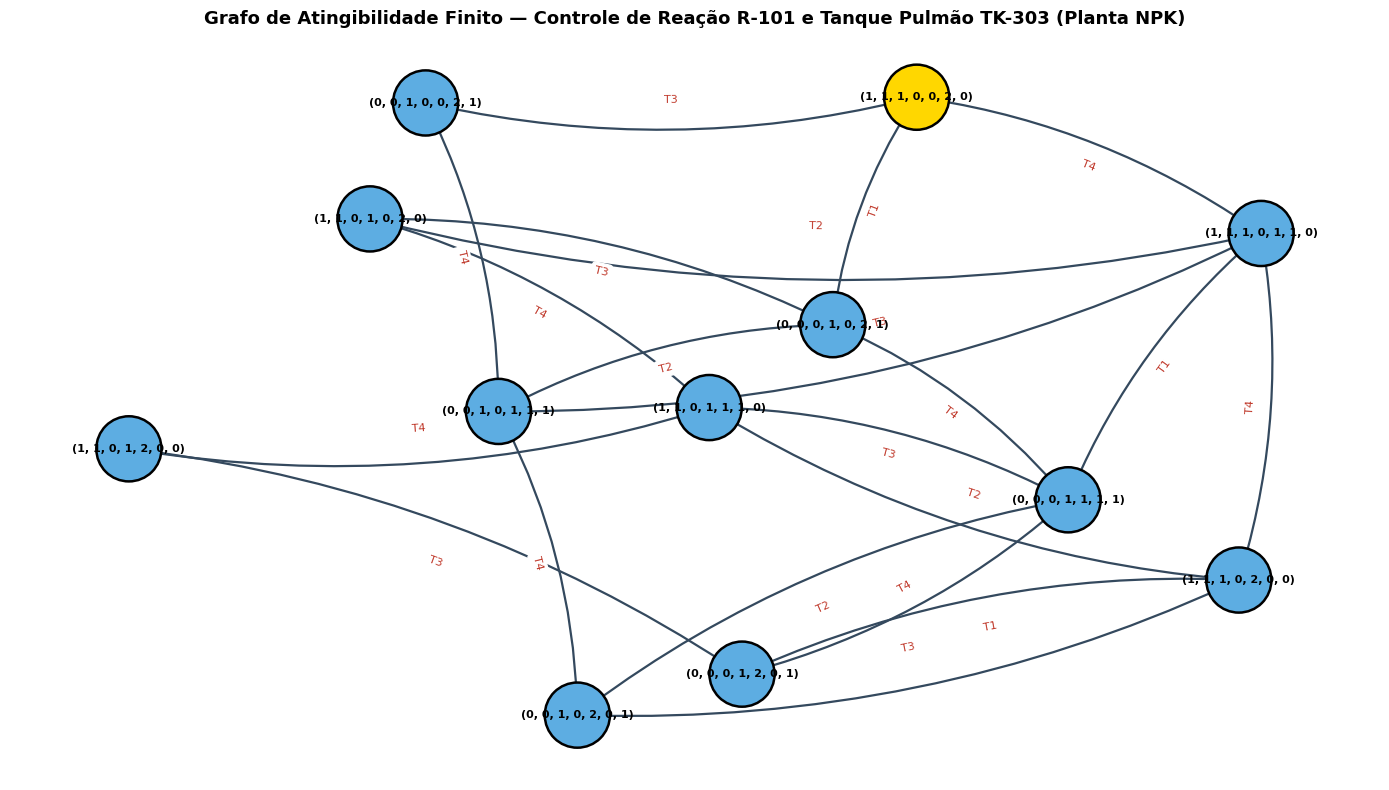

In [5]:
def plotar_grafo_atingibilidade(grafo, m0, titulo):
    fig, ax = plt.subplots(figsize=(14, 8))
    pos = nx.spring_layout(grafo, seed=42, k=1.4)

    cores = ["#FFD700" if n == m0 else "#5DADE2" for n in grafo.nodes]
    labels_nos = {n: d["label"] for n, d in grafo.nodes(data=True)}

    nx.draw_networkx_nodes(grafo, pos, node_color=cores, node_size=2200, edgecolors="black", linewidths=1.8, ax=ax)
    nx.draw_networkx_labels(grafo, pos, labels=labels_nos, font_size=8, font_weight="bold", ax=ax)

    nx.draw_networkx_edges(
        grafo, pos,
        edge_color="#34495E",
        width=1.6,
        arrows=True,
        arrowsize=18,
        connectionstyle="arc3,rad=0.12",
        ax=ax
    )

    edge_labels = {(u, v): d["transicao"].split("_")[0] for u, v, d in grafo.edges(data=True)}
    nx.draw_networkx_edge_labels(grafo, pos, edge_labels=edge_labels, font_size=8, font_color="#C0392B", ax=ax)

    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

plotar_grafo_atingibilidade(
    grafo_B,
    M0_B,
    "Grafo de Atingibilidade Finito — Controle de Reação R-101 e Tanque Pulmão TK-303 (Planta NPK)"
)